# 01 Data Understanding

**Project:** CreditLens, SME credit risk scoring for guaranteed loans
**CRISP-DM phase:** Data Understanding (brief stages 2 and 3: data collection and data understanding)
**Author:** Salem Adel Salem Alshamlan Almarri

**Purpose.** Before cleaning anything we want to know exactly what is wrong with the raw file. This notebook profiles every column, measures each quality problem with counts, and collects the evidence that decides the cleaning rules in notebook 02. It closes with a numbered register of every issue and the fix we plan.

**Inputs:** `data/raw/SBAnational.csv` (US Small Business Administration 7(a) loans, Kaggle copy of Li, Mickel and Taylor, 2018).

**Outputs:** figures `docs/figures/fig01_*.png` and the data quality issues register at the end of this notebook.

## 1. Business context in brief

A bank lending to small and medium enterprises under a government guarantee scheme wants to decide, at application time, whether to approve, refer or decline a loan. The SBA guarantees part of each loan and the bank carries the rest, so a charged-off loan costs the bank the unguaranteed principal plus workout costs. Our target is `Default` = 1 when `MIS_Status` is `CHGOFF` and 0 when it is `P I F` (paid in full). The full problem statement is in `docs/business_problem.md`.

For data understanding this has two consequences. First, any column that is only known after the outcome (`ChgOffDate`, `ChgOffPrinGr`, `BalanceGross`) must be identified now so it never becomes a feature. Second, every quality problem matters in proportion to how it could distort the default rate, so for the coded columns we look at default rates, not just counts.

## 2. Setup

We add the repository root to the Python path so that the notebook can import the shared configuration and the cleaning module from `src`. All paths come from `src/config.py`, so nothing depends on where the repository sits on a particular computer.

In [1]:
import sys
from pathlib import Path

# Make the repository root importable whether the notebook runs from notebooks/ or the root
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from src import config
from src.cleaning import load_raw, parse_currency, parse_sba_date, quality_assessment

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# One white, consistent style for every figure in the project
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})
P = config.PALETTE
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    """Save a figure to docs/figures at 150 dpi and print the relative path."""
    path = config.FIGURES_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved {path.relative_to(config.PROJECT_ROOT)}")

## 3. Loading the raw file

We read the CSV once and keep it in memory for the whole notebook. Only empty fields count as missing: the pandas default would also turn text such as "NA" into a missing value, which could hide a real name or city. Everything else is left exactly as stored, so the problems we find are the problems in the file.

In [2]:
raw = load_raw(config.RAW_DATA_PATH)

print(f"File: {config.RAW_DATA_PATH.relative_to(config.PROJECT_ROOT)}")
print(f"Size on disk: {config.RAW_DATA_PATH.stat().st_size / 1e6:,.0f} MB")
print(f"Rows: {raw.shape[0]:,}   Columns: {raw.shape[1]}")
print(f"Memory in pandas: {raw.memory_usage(deep=True).sum() / 1e6:,.0f} MB")

File: data/raw/SBAnational.csv
Size on disk: 179 MB
Rows: 899,164   Columns: 27


Memory in pandas: 930 MB


The file has 899,164 loans and 27 columns, which meets the course requirement of at least 200,000 rows and 20 columns. Each row is one loan guaranteed by the SBA.

## 4. Data types and first rows

The types pandas infers already tell us a lot: a column that should be a number but comes back as `object` (text) contains something that is not a number.

In [3]:
# Inferred type of each column next to one example value
types = pd.DataFrame({"dtype": raw.dtypes.astype(str), "first value": raw.iloc[0]})
types

,dtype,first value
LoanNr_ChkDgt,int64,1000014003
Name,object,ABC HOBBYCRAFT
City,object,EVANSVILLE
State,object,IN
Zip,int64,47711
Bank,object,FIFTH THIRD BANK
BankState,object,OH
NAICS,int64,451120
ApprovalDate,object,28-Feb-97
ApprovalFY,object,1997


In [4]:
raw.head()

,LoanNr_ChkDgt,Name,City,State,Zip,Bank,BankState,NAICS,ApprovalDate,ApprovalFY,Term,NoEmp,NewExist,CreateJob,RetainedJob,FranchiseCode,UrbanRural,RevLineCr,LowDoc,ChgOffDate,DisbursementDate,DisbursementGross,BalanceGross,MIS_Status,ChgOffPrinGr,GrAppv,SBA_Appv
0,1000014003,ABC HOBBYCRAFT,EVANSVILLE,IN,47711,FIFTH THIRD BANK,OH,451120,28-Feb-97,1997,84,4,2.000,0,0,1,0,N,Y,NaN,28-Feb-99,"$60,000.00",$0.00,P I F,$0.00,"$60,000.00","$48,000.00"
1,1000024006,LANDMARK BAR & GRILLE (THE),NEW PARIS,IN,46526,1ST SOURCE BANK,IN,722410,28-Feb-97,1997,60,2,2.000,0,0,1,0,N,Y,NaN,31-May-97,"$40,000.00",$0.00,P I F,$0.00,"$40,000.00","$32,000.00"
2,1000034009,"WHITLOCK DDS, TODD M.",BLOOMINGTON,IN,47401,GRANT COUNTY STATE BANK,IN,621210,28-Feb-97,1997,180,7,1.000,0,0,1,0,N,N,NaN,31-Dec-97,"$287,000.00",$0.00,P I F,$0.00,"$287,000.00","$215,250.00"
3,1000044001,"BIG BUCKS PAWN & JEWELRY, LLC",BROKEN ARROW,OK,74012,1ST NATL BK & TR CO OF BROKEN,OK,0,28-Feb-97,1997,60,2,1.000,0,0,1,0,N,Y,NaN,30-Jun-97,"$35,000.00",$0.00,P I F,$0.00,"$35,000.00","$28,000.00"
4,1000054004,"ANASTASIA CONFECTIONS, INC.",ORLANDO,FL,32801,FLORIDA BUS. DEVEL CORP,FL,0,28-Feb-97,1997,240,14,1.000,7,7,1,0,N,N,NaN,14-May-97,"$229,000.00",$0.00,P I F,$0.00,"$229,000.00","$229,000.00"


Five currency columns (`DisbursementGross`, `BalanceGross`, `ChgOffPrinGr`, `GrAppv`, `SBA_Appv`) are text such as `$60,000.00 ` with a dollar sign, commas and a trailing space. The three date columns are text in the form `28-Feb-97`. `ApprovalFY` should be a year but is text, and `NewExist` is a float only because it has missing values. In total nine columns that should hold numbers or dates are stored as text, so the file cannot be used for modelling as it is.

## 5. Column-by-column profile

For each column we record the type, the number of non-missing values, the number of distinct values, a few example values and the issue we found. The issue column summarises the checks in the sections that follow.

In [5]:
# Issue found for each column, based on the checks in sections 6 to 12
issues = {
    "LoanNr_ChkDgt": "Identifier, unique per row; never a feature",
    "Name": "Identifier; 3 missing; used only for the near-duplicate check",
    "City": "30 missing; free text with some junk values",
    "State": "14 missing",
    "Zip": "283 rows with Zip 0 (not a real ZIP code)",
    "Bank": "1,559 missing",
    "BankState": "1,566 missing",
    "NAICS": "201,948 rows with 0 (industry unknown)",
    "ApprovalDate": "Text dd-Mon-yy; two-digit year needs a century rule",
    "ApprovalFY": "Text; 18 values '1976A'",
    "Term": "810 loans with Term 0 months",
    "NoEmp": "Placeholder 9999 and extreme values",
    "NewExist": "136 missing and 1,034 coded 0 (only 1 and 2 are valid)",
    "CreateJob": "Extreme values up to 8,800",
    "RetainedJob": "Extreme values up to 9,500",
    "FranchiseCode": "0 and 1 both mean no franchise",
    "UrbanRural": "323,167 coded 0 (undefined)",
    "RevLineCr": "4,528 missing and 18 invalid codes besides Y and N",
    "LowDoc": "2,582 missing and 6 invalid codes besides Y and N",
    "ChgOffDate": "Post-outcome (leakage); mismatches with MIS_Status",
    "DisbursementDate": "2,368 missing; some dates before approval or impossible",
    "DisbursementGross": "Currency text; 196 zeros",
    "BalanceGross": "Currency text; post-outcome (leakage); almost always 0",
    "MIS_Status": "Target source; 1,997 missing",
    "ChgOffPrinGr": "Currency text; post-outcome (leakage)",
    "GrAppv": "Currency text",
    "SBA_Appv": "Currency text",
}

profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "missing": raw.isna().sum(),
    "unique": raw.nunique(dropna=True),
    # three distinct example values, shown with quotes so trailing spaces are visible
    "examples": [", ".join(repr(v) for v in raw[c].dropna().unique()[:3]) for c in raw.columns],
    "issue_found": pd.Series(issues),
})
profile

,dtype,non_null,missing,unique,examples,issue_found
LoanNr_ChkDgt,int64,899164,0,899164,"np.int64(1000014003), np.int64(1000024006), np...","Identifier, unique per row; never a feature"
Name,object,899161,3,779586,"'ABC HOBBYCRAFT', 'LANDMARK BAR & GRILLE (THE)...",Identifier; 3 missing; used only for the near-...
City,object,899134,30,32581,"'EVANSVILLE', 'NEW PARIS', 'BLOOMINGTON'",30 missing; free text with some junk values
State,object,899150,14,51,"'IN', 'OK', 'FL'",14 missing
Zip,int64,899164,0,33611,"np.int64(47711), np.int64(46526), np.int64(47401)",283 rows with Zip 0 (not a real ZIP code)
Bank,object,897605,1559,5802,"'FIFTH THIRD BANK', '1ST SOURCE BANK', 'GRANT ...","1,559 missing"
BankState,object,897598,1566,56,"'OH', 'IN', 'OK'","1,566 missing"
NAICS,int64,899164,0,1312,"np.int64(451120), np.int64(722410), np.int64(6...","201,948 rows with 0 (industry unknown)"
ApprovalDate,object,899164,0,9859,"'28-Feb-97', '2-Jun-80', '7-Feb-06'",Text dd-Mon-yy; two-digit year needs a century...
ApprovalFY,object,899164,0,52,"'1997', '1980', '2006'",Text; 18 values '1976A'


The profile shows that almost every column has some problem. The most serious for modelling are the coded columns (`RevLineCr`, `LowDoc`, `NewExist`, `UrbanRural`), because invalid codes affect hundreds of thousands of rows, and the text-typed money and date columns, because nothing numeric can be computed until they are parsed.

## 6. Missing values

We count missing cells per column and plot the columns that have any.

In [6]:
missing = raw.isna().sum()
missing = missing[missing > 0].sort_values()
missing_table = pd.DataFrame({"missing": missing, "percent": 100 * missing / len(raw)})
print(f"Total missing cells: {raw.isna().sum().sum():,} of {raw.size:,} ({100 * raw.isna().sum().sum() / raw.size:.2f}%)")
missing_table.sort_values("missing", ascending=False)

Total missing cells: 751,248 of 24,277,428 (3.09%)


,missing,percent
ChgOffDate,736465,81.906
RevLineCr,4528,0.504
LowDoc,2582,0.287
DisbursementDate,2368,0.263
MIS_Status,1997,0.222
BankState,1566,0.174
Bank,1559,0.173
NewExist,136,0.015
City,30,0.003
State,14,0.002


Saved docs/figures/fig01_missing_values.png


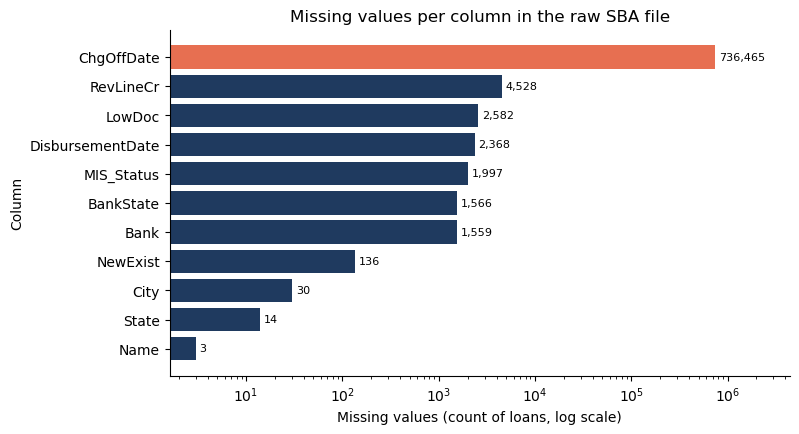

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colours = [P["red"] if c == "ChgOffDate" else P["navy"] for c in missing.index]
ax.barh(missing.index, missing.values, color=colours)
ax.set_xscale("log")
ax.set_xlabel("Missing values (count of loans, log scale)")
ax.set_ylabel("Column")
ax.set_title("Missing values per column in the raw SBA file")
for y, v in enumerate(missing.values):
    ax.text(v * 1.1, y, f"{v:,}", va="center", fontsize=8)
ax.set_xlim(right=missing.max() * 6)
save_fig(fig, "fig01_missing_values.png")
plt.show()

`ChgOffDate` (red) is missing for 736,465 loans, but that is by design: a loan that was repaid has no charge-off date, and the column is post-outcome anyway. Apart from it only 14,783 cells are missing, spread over nine columns, with `RevLineCr` (4,528), `LowDoc` (2,582) and `DisbursementDate` (2,368) the largest. For the bank this means missing data is a small problem compared with wrong codes; it is the 1,997 loans with no `MIS_Status` that matter most, because their outcome is unknown and they cannot be used to train or test a default model.

## 7. Invalid codes and what they tell us

`RevLineCr` and `LowDoc` should only contain Y or N, `NewExist` should be 1 (existing business) or 2 (new business) and `UrbanRural` should be 1 (urban) or 2 (rural), with 0 meaning undefined (Li, Mickel and Taylor, 2018, Table 1). For each code we show the count, the default rate and a few loan characteristics. If an invalid code has the same profile as a valid one it is probably a different spelling of that value; if it behaves differently it should stay separate.

We first parse the amounts and the status we need for these tables. This is a temporary working copy; the real parsing is done in notebook 02.

In [8]:
# Temporary numeric helpers for the evidence tables (the cleaning itself is done in notebook 02)
status = raw["MIS_Status"]
default = np.where(status.isna(), np.nan, (status == config.DEFAULT_LABEL).astype(float))
gr_appv = parse_currency(raw["GrAppv"])
sba_appv = parse_currency(raw["SBA_Appv"])
disb_gross = parse_currency(raw["DisbursementGross"])
evidence = pd.DataFrame({
    "default": default,
    "gr_appv": gr_appv,
    "term": raw["Term"],
    "guarantee_50": (sba_appv / gr_appv).round(2).eq(0.50),   # 50% guarantee, typical of SBAExpress loans
    "disbursed_above_approved": disb_gross > gr_appv,          # typical of revolving lines that are redrawn
    "lowdoc_y": raw["LowDoc"].eq("Y"),
    "approval_fy": pd.to_numeric(raw["ApprovalFY"].str.replace(r"\D", "", regex=True)),
})


def code_profile(col):
    """Count, default rate and loan profile for each code of a column (NaN shown as 'missing')."""
    codes = raw[col].astype("string").fillna("missing")
    out = evidence.groupby(codes).agg(
        loans=("default", "size"),
        default_rate=("default", "mean"),
        median_approved_usd=("gr_appv", "median"),
        median_term_months=("term", "median"),
        share_50pct_guarantee=("guarantee_50", "mean"),
        share_disbursed_above_approved=("disbursed_above_approved", "mean"),
        median_approval_fy=("approval_fy", "median"),
    )
    out.insert(1, "share_of_loans", out["loans"] / len(raw))
    return out.sort_values("loans", ascending=False)

### 7.1 RevLineCr (revolving line of credit)

In [9]:
rev_profile = code_profile("RevLineCr")
rev_profile

,loans,share_of_loans,default_rate,median_approved_usd,median_term_months,share_50pct_guarantee,share_disbursed_above_approved,median_approval_fy
RevLineCr,,,,,,,,
N,420288,0.467,0.146,"118,000.000",84.000,0.158,0.010,"1,997.000"
0,257602,0.286,0.150,"125,900.000",84.000,0.198,0.000,"2,002.000"
Y,201397,0.224,0.254,"30,000.000",75.000,0.964,0.708,"2,006.000"
T,15284,0.017,0.431,"35,000.000",64.000,0.963,0.615,"2,005.000"
missing,4528,0.005,0.025,"100,000.000",87.000,0.001,0.000,"1,995.000"
1,23,0.000,0.087,"165,000.000",108.000,0.000,0.000,"1,999.000"
R,14,0.000,0.071,"372,500.000",15.000,0.000,0.000,"2,001.000"
`,11,0.000,0.000,"87,650.000",70.000,0.000,0.000,"1,996.000"
2,6,0.000,0.000,"378,000.000",12.000,0.000,0.000,"2,000.000"


Besides Y and N there are 18 other codes. Two of them are large: `0` (257,602 loans) and `T` (15,284 loans). The remaining 16 codes together cover 65 loans, and 4,528 values are missing.

The `0` group looks like N on every measure: a default rate of 15.0% against 14.6% for N, a median approved amount of 125,900 USD against 118,000 USD, the same median term of 84 months, almost no loans disbursed above the approved amount, and few 50% guarantees. The `T` group looks like Y on the structural measures: 96.4% of Y loans and 96.3% of T loans carry a 50% guarantee (against 15.8% for N and 19.8% for `0`), 71% of Y and 62% of T loans were disbursed above the approved amount (the signature of a revolving line that is drawn again), and neither group contains any LowDoc loans. Its median amount (35,000 USD) and term (64 months) are close to Y (30,000 USD, 75 months) and far from N.

The year pattern below adds a second piece of evidence.

In [10]:
# Which RevLineCr codes were used in which approval years
main_codes = raw["RevLineCr"].where(raw["RevLineCr"].isin(["Y", "N", "0", "T"]), "other").fillna("missing")
rev_by_year = pd.crosstab(evidence["approval_fy"], main_codes).loc[1990:2014]

# Default rate of the main codes within the same approval years (2003 to 2007), to separate code from timing
same_years = evidence["approval_fy"].between(2003, 2007)
print("Default rate by code, approvals 2003 to 2007:")
print(evidence[same_years].groupby(main_codes[same_years])["default"].mean().loc[["N", "0", "Y", "T"]].round(3).to_dict())
rev_by_year

Default rate by code, approvals 2003 to 2007:
{'N': 0.338, '0': 0.197, 'Y': 0.287, 'T': 0.531}


RevLineCr,0,N,T,Y,other
approval_fy,,,,,
1990,0,14859,0,0,0
1991,0,15662,0,4,0
1992,0,20818,1,66,0
1993,0,23272,1,32,0
1994,0,31586,2,10,0
1995,2540,38958,27,290,3943
1996,9656,29860,146,420,30
1997,12600,23250,353,1527,18
1998,17372,15638,182,2806,18


Code `0` appears only between 1995 and 2009, exactly while the number of N codes falls, and disappears again when N recovers in 2010. This looks like a period in which one recording system wrote "no" as `0`. `T` is used alongside Y in the same years Y grows.

The one point against merging `T` into Y is its default rate: 43.1% against 25.4% for Y. Part of this is timing (T loans are concentrated in 2003 to 2007, the cohorts hit hardest by the recession), but even within those years T defaults more often (53.1% against 28.7%). Within the same years `0` also defaults less than N (19.7% against 33.8%), so the match between `0` and N rests on loan structure and timing of use rather than on identical risk. Our conclusion is to map `0` to N and `T` to Y, because the structure of the loans says that is what they are, and to keep the original code in a separate column `RevLineCr_raw` so that notebook 03 can test whether the T code carries extra risk signal. The 65 loans with rare codes and the 4,528 missing values become an explicit `Unknown` level.

Saved docs/figures/fig01_revlinecr_code_profile.png


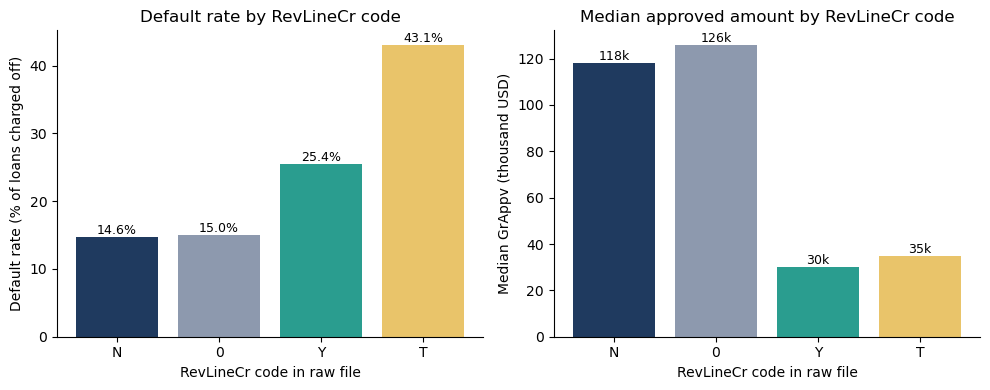

In [11]:
# Default rate and median amount for the four main RevLineCr codes
main = rev_profile.loc[["N", "0", "Y", "T"]]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
colours = [P["navy"], P["grey"], P["teal"], P["amber"]]
axes[0].bar(main.index, 100 * main["default_rate"], color=colours)
axes[0].set_title("Default rate by RevLineCr code")
axes[0].set_xlabel("RevLineCr code in raw file")
axes[0].set_ylabel("Default rate (% of loans charged off)")
axes[1].bar(main.index, main["median_approved_usd"] / 1000, color=colours)
axes[1].set_title("Median approved amount by RevLineCr code")
axes[1].set_xlabel("RevLineCr code in raw file")
axes[1].set_ylabel("Median GrAppv (thousand USD)")
for ax, col, scale, fmt in [(axes[0], "default_rate", 100, "{:.1f}%"), (axes[1], "median_approved_usd", 1 / 1000, "{:.0f}k")]:
    for x, v in enumerate(main[col] * scale):
        ax.text(x, v, fmt.format(v), ha="center", va="bottom", fontsize=9)
fig.tight_layout()
save_fig(fig, "fig01_revlinecr_code_profile.png")
plt.show()

The chart shows the pairing clearly: `0` sits next to N in both panels and `T` sits next to Y on loan size, while its default rate is higher still. For the bank, revolving lines are small, mostly 50% guaranteed and much riskier than term loans, so getting this mapping right matters for the model.

### 7.2 LowDoc (low documentation loan programme)

In [12]:
low_profile = code_profile("LowDoc")
low_profile

,loans,share_of_loans,default_rate,median_approved_usd,median_term_months,share_50pct_guarantee,share_disbursed_above_approved,median_approval_fy
LowDoc,,,,,,,,
N,782822,0.871,0.187,"100,000.000",84.000,0.417,0.199,"2,003.000"
Y,110335,0.123,0.090,"60,000.000",84.000,0.000,0.000,"1,998.000"
missing,2582,0.003,0.387,"42,950.000",84.000,0.013,0.001,"2,009.000"
0,1491,0.002,0.034,"275,000.000",239.000,0.008,0.001,"1,995.000"
C,758,0.001,0.099,"243,000.000",120.000,0.008,0.032,"2,002.000"
S,603,0.001,0.448,"25,000.000",84.000,0.012,0.000,"2,009.000"
A,497,0.001,0.321,"75,000.000",61.000,0.014,0.002,"2,008.000"
R,75,0.000,0.338,"50,000.000",64.000,0.027,0.000,"2,009.000"
1,1,0.000,0.000,"797,345.000",252.000,0.000,0.000,"2,006.000"


LowDoc has six invalid codes (`0`, `C`, `S`, `A`, `R`, `1`) covering 3,425 loans, plus 2,582 missing values. Unlike RevLineCr, none of these groups has a profile that matches Y or N. Code `0` has a 3.4% default rate and a median term of 239 months (real-estate-like loans), while `S` (44.8%) and the missing group (38.7%) are far riskier than either N (18.7%) or Y (9.0%). Mapping any of them to Y or N would be a guess, and the missing group's high default rate is a signal worth keeping. All non-Y/N values therefore become `Unknown`.

### 7.3 NewExist (existing or new business)

In [13]:
new_profile = code_profile("NewExist")
new_profile

,loans,share_of_loans,default_rate,median_approved_usd,median_term_months,share_50pct_guarantee,share_disbursed_above_approved,median_approval_fy
NewExist,,,,,,,,
1.0,644869,0.717,0.171,"100,000.000",84.000,0.390,0.191,"2,002.000"
2.0,253125,0.282,0.188,"75,000.000",84.000,0.295,0.130,"2,003.000"
0.0,1034,0.001,0.061,"215,000.000",120.000,0.040,0.009,"1,999.000"
missing,136,0.000,0.104,"69,750.000",84.000,0.640,0.250,"2,010.000"


1,034 loans are coded 0 and 136 are missing. Both groups default much less (6.1% and 10.4%) than existing (17.1%) or new businesses (18.8%), so they do not look like either valid group. We keep them as `Unknown` rather than filling with the mode (existing), which would move about 1,170 low-risk loans into the existing-business group.

### 7.4 UrbanRural

In [14]:
urban_profile = code_profile("UrbanRural")
urban_profile

,loans,share_of_loans,default_rate,median_approved_usd,median_term_months,share_50pct_guarantee,share_disbursed_above_approved,median_approval_fy
UrbanRural,,,,,,,,
1,470654,0.523,0.245,"53,000.000",84.000,0.561,0.277,"2,005.000"
0,323167,0.359,0.071,"126,000.000",108.000,0.045,0.009,"1,995.000"
2,105343,0.117,0.188,"75,000.000",84.000,0.451,0.217,"2,005.000"


This is the largest coding problem: 323,167 loans (35.9%) are coded 0, undefined. Their default rate is 7.1%, against 24.5% for urban and 18.8% for rural loans, and their median approval year is earlier than both valid groups. The 0 code is clearly not a random gap; it is mostly older loans recorded before the field was filled in. Imputing the mode (urban) would put a third of the data, with a very different default rate, into the urban group and weaken the difference between urban and rural. We keep 0 as `Unknown`.

## 8. Currency, date and fiscal year formats

The currency columns need the dollar sign, commas and trailing space removed. The dates need more care because the year has only two digits.

In [15]:
# Raw currency strings next to the parsed value
currency_cols = ["DisbursementGross", "GrAppv", "SBA_Appv", "BalanceGross", "ChgOffPrinGr"]
pd.DataFrame({c: raw[c].head(3).map(repr) for c in currency_cols}).assign(parsed_GrAppv=gr_appv.head(3))

,DisbursementGross,GrAppv,SBA_Appv,BalanceGross,ChgOffPrinGr,parsed_GrAppv
0,"'$60,000.00 '","'$60,000.00 '","'$48,000.00 '",'$0.00 ','$0.00 ',"60,000.000"
1,"'$40,000.00 '","'$40,000.00 '","'$32,000.00 '",'$0.00 ','$0.00 ',"40,000.000"
2,"'$287,000.00 '","'$287,000.00 '","'$215,250.00 '",'$0.00 ','$0.00 ',"287,000.000"


In [16]:
# How Python's default century rule and our rule read the same date strings
approval_text = raw["ApprovalDate"]
default_rule = pd.to_datetime(approval_text, format="%d-%b-%y")
our_rule = parse_sba_date(approval_text)
wrong = default_rule.dt.year > 2014
print(f"Approval dates read as a future year by the default rule: {wrong.sum()}")
pd.DataFrame({"raw text": approval_text[wrong], "default rule": default_rule[wrong].dt.date,
              "our rule": our_rule[wrong].dt.date, "ApprovalFY": raw.loc[wrong, "ApprovalFY"]})

Approval dates read as a future year by the default rule: 9


,raw text,default rule,our rule,ApprovalFY
38920,7-Dec-61,2061-12-07,1961-12-07,1962
44932,27-Nov-64,2064-11-27,1964-11-27,1965
49244,18-May-66,2066-05-18,1966-05-18,1966
434334,28-Feb-67,2067-02-28,1967-02-28,1967
683481,20-Jul-67,2067-07-20,1967-07-20,1968
689069,25-Apr-67,2067-04-25,1967-04-25,1967
697801,9-Feb-68,2068-02-09,1968-02-09,1968
720402,3-Dec-68,2068-12-03,1968-12-03,1969
732056,24-Sep-68,2068-09-24,1968-09-24,1969


Python reads two-digit years 00 to 68 as 2000 to 2068, so nine loans approved in the 1960s would appear as approved in 2061 to 2068. The `ApprovalFY` column confirms they are 1960s loans. Our rule treats a two-digit year above the current year's last two digits as 19xx, which fixes all nine. The same problem would also affect any disbursement or charge-off dates with years in that range.

In [17]:
# Dates that are still impossible for this dataset after the century rule (outside 1960 to 2014)
date_check = {c: parse_sba_date(raw[c]) for c in ["ApprovalDate", "DisbursementDate", "ChgOffDate"]}
for col, d in date_check.items():
    bad = d.notna() & ((d < "1960-01-01") | (d > "2014-12-31"))
    print(f"{col}: {bad.sum()} impossible dates", list(raw.loc[bad, col]))

# ApprovalFY values that are not plain years
fy_text = raw["ApprovalFY"].astype(str)
print("ApprovalFY values with non-digits:", fy_text[fy_text.str.contains(r"\D")].value_counts().to_dict())

ApprovalDate: 0 impossible dates []
DisbursementDate: 3 impossible dates ['17-Sep-48', '14-Apr-20', '18-Jun-28']
ChgOffDate: 1 impossible dates ['22-Oct-26']


ApprovalFY values with non-digits: {'1976A': 18}


Four dates remain impossible even with the century rule: three disbursement dates (in 1928, 1948 and 2020) and one charge-off date in 2026, all outside the period the data covers. They are typing errors and will be set to missing. `ApprovalFY` contains 18 values of `1976A`; stripping the letter gives the year.

## 9. Outliers and impossible numeric values

In [18]:
numeric_cols = ["NoEmp", "Term", "CreateJob", "RetainedJob"]
summary = raw[numeric_cols].describe(percentiles=[0.5, 0.99, 0.999]).T
summary["zeros"] = (raw[numeric_cols] == 0).sum()
summary

,count,mean,std,min,50%,99%,99.9%,max,zeros
NoEmp,"899,164.000",11.411,74.108,0.000,4.000,95.000,300.000,"9,999.000",6631
Term,"899,164.000",110.773,78.857,0.000,84.000,300.000,309.000,569.000,810
CreateJob,"899,164.000",8.430,236.688,0.000,0.000,30.000,200.000,"8,800.000",629248
RetainedJob,"899,164.000",10.797,237.121,0.000,1.000,55.000,276.674,"9,500.000",440403


In [19]:
# NoEmp placeholder and the largest values
print("Loans with NoEmp = 9999:", (raw["NoEmp"] == 9999).sum())
print("Largest NoEmp values:", sorted(raw["NoEmp"].nlargest(8).tolist(), reverse=True))

# Term of 0 months, with its default rate
term0 = raw["Term"] == 0
print(f"Loans with Term = 0: {term0.sum()}, default rate {np.nanmean(default[term0]):.1%} "
      f"(all loans {np.nanmean(default):.1%})")

# Job counts far above the 99.9th percentile
for col in ["CreateJob", "RetainedJob"]:
    p999 = raw[col].quantile(0.999)
    print(f"{col}: 99.9th percentile {p999:,.0f}, max {raw[col].max():,}, loans above p99.9: {(raw[col] > p999).sum()}")

Loans with NoEmp = 9999: 4
Largest NoEmp values: [9999, 9999, 9999, 9999, 9992, 9945, 9090, 9000]
Loans with Term = 0: 810, default rate 91.1% (all loans 17.6%)
CreateJob: 99.9th percentile 200, max 8,800, loans above p99.9: 870
RetainedJob: 99.9th percentile 277, max 9,500, loans above p99.9: 900


Saved docs/figures/fig01_numeric_outliers.png


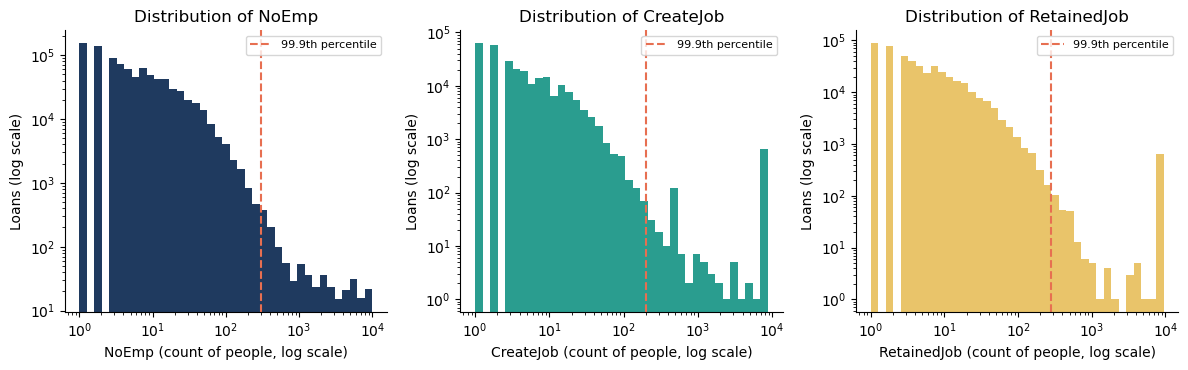

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, col, colour in zip(axes, ["NoEmp", "CreateJob", "RetainedJob"], [P["navy"], P["teal"], P["amber"]]):
    values = raw[col]
    bins = np.logspace(0, np.log10(values.max() + 1), 40)
    ax.hist(values[values > 0], bins=bins, color=colour)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.axvline(values.quantile(0.999), color=P["red"], linestyle="--", label="99.9th percentile")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(f"{col} (count of people, log scale)")
    ax.set_ylabel("Loans (log scale)")
    ax.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "fig01_numeric_outliers.png")
plt.show()

All three counts are heavily right-skewed. The 99.9th percentile of `NoEmp` is 300 employees, but the maximum is 9,999, which is a placeholder rather than a real firm (four loans). `CreateJob` and `RetainedJob` reach 8,800 and 9,500 jobs for loans whose median is 0 and 1 jobs; a small business loan cannot create thousands of jobs, so these are entry errors or unit mistakes. For a credit model such values would dominate any scaled feature, so they need treatment.

`Term` is the loan length in months. 810 loans have a term of 0, which is impossible for a loan that was disbursed. These loans default at 91.1%, against 17.6% overall. That is far too high to be chance: a term of 0 was most likely recorded after the loan failed, so the zero itself is post-outcome information. Dropping the rows would remove a group that is almost all defaults, and keeping a "term was zero" indicator as a feature would leak the outcome. Notebook 02 examines this trade-off.

## 10. Logical inconsistencies

Here we check whether values agree with each other.

In [21]:
approval = date_check["ApprovalDate"]
disbursement = date_check["DisbursementDate"]
chgoff_date = date_check["ChgOffDate"]
lag_days = (disbursement - approval).dt.days
print(f"Median days from approval to disbursement: {lag_days.median():.0f}")
chgoff_prin = parse_currency(raw["ChgOffPrinGr"])
ratio = disb_gross / gr_appv

checks = pd.Series({
    "Disbursement before approval (any)": (lag_days < 0).sum(),
    "Disbursement more than 30 days before approval": (lag_days < -30).sum(),
    "SBA_Appv greater than GrAppv": (sba_appv > gr_appv).sum(),
    "Paid in full but ChgOffDate present": ((status == "P I F") & chgoff_date.notna()).sum(),
    "Charged off but ChgOffDate missing": ((status == "CHGOFF") & chgoff_date.isna()).sum(),
    "Paid in full but ChgOffPrinGr above 0": ((status == "P I F") & (chgoff_prin > 0)).sum(),
    "Zip equal to 0": (raw["Zip"] == 0).sum(),
    "DisbursementGross equal to 0": (disb_gross == 0).sum(),
    "DisbursementGross more than twice GrAppv": (ratio > 2).sum(),
    "DisbursementGross under half of GrAppv": (ratio < 0.5).sum(),
    "BalanceGross above 0": (parse_currency(raw["BalanceGross"]) > 0).sum(),
}, name="loans")
checks.to_frame()

Median days from approval to disbursement: 59


,loans
Disbursement before approval (any),809
Disbursement more than 30 days before approval,135
SBA_Appv greater than GrAppv,0
Paid in full but ChgOffDate present,4927
Charged off but ChgOffDate missing,47
Paid in full but ChgOffPrinGr above 0,4884
Zip equal to 0,283
DisbursementGross equal to 0,196
DisbursementGross more than twice GrAppv,65967
DisbursementGross under half of GrAppv,4132


MIS_Status of loans with DisbursementGross = 0: {nan: 196}


Saved docs/figures/fig01_disbursement_lag.png


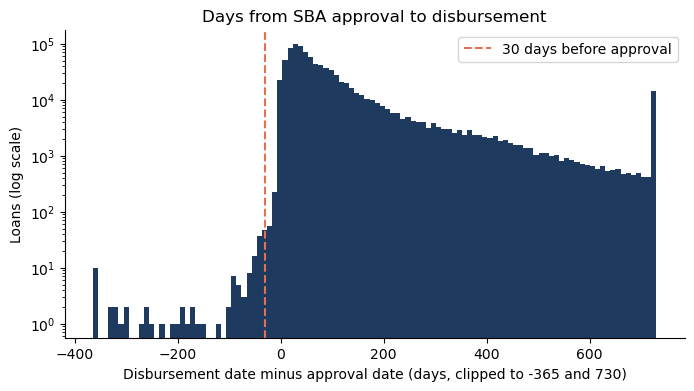

In [22]:
# Status of the loans with zero disbursement, and the distribution of the disbursement lag
print("MIS_Status of loans with DisbursementGross = 0:", status[disb_gross == 0].value_counts(dropna=False).to_dict())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(lag_days.clip(-365, 730).dropna(), bins=110, color=P["navy"])
ax.axvline(-30, color=P["red"], linestyle="--", label="30 days before approval")
ax.set_yscale("log")
ax.set_title("Days from SBA approval to disbursement")
ax.set_xlabel("Disbursement date minus approval date (days, clipped to -365 and 730)")
ax.set_ylabel("Loans (log scale)")
ax.legend()
save_fig(fig, "fig01_disbursement_lag.png")
plt.show()

Most loans are disbursed within a few months of approval (median 59 days). 809 loans show a disbursement before approval; most are within a month, which can happen when a bank advances funds while the guarantee is being processed, but 135 are more than 30 days early. We will keep them and add a flag rather than drop them, because the other fields of these loans look normal.

`SBA_Appv` never exceeds `GrAppv` in this file, so that rule is a safeguard only. The status and charge-off date disagree for 4,974 loans (4,927 paid loans with a charge-off date, 47 charged-off loans without one). Since `ChgOffDate` is post-outcome and never a feature, we keep `MIS_Status` as the label and only flag the mismatch. The 196 loans with zero disbursement all have a missing status, so they leave with the unknown-label rows. Disbursing more than the approved amount (65,967 loans above twice `GrAppv`) is common for revolving lines that are redrawn, so it is a feature to engineer in notebook 03, not an error. `BalanceGross` is above 0 for only 14 loans, which confirms it carries almost no information.

## 11. Duplicates and near-duplicates

In [23]:
key = ["Name", "City", "State", "ApprovalDate", "GrAppv"]
print("Exact duplicate rows:", raw.duplicated().sum())
print("Duplicate loan numbers:", raw["LoanNr_ChkDgt"].duplicated().sum())
print("Rows identical in every column except the loan number:", raw.drop(columns="LoanNr_ChkDgt").duplicated().sum())
near = raw.duplicated(subset=key, keep="first")
print(f"Near-duplicates on {key}: {near.sum():,} extra rows")

# How many of those also agree on further loan details (a stricter key)
for extra in [["Term"], ["Term", "Bank"], ["Term", "Bank", "DisbursementGross", "DisbursementDate"]]:
    print(f"  ... also matching on {extra}: {raw.duplicated(subset=key + extra).sum():,}")
groups = raw[raw.duplicated(subset=key, keep=False)].groupby(key)["MIS_Status"].nunique()
print(f"Near-duplicate groups whose copies have different outcomes: {(groups > 1).sum()}")

# One example group of near-duplicates
in_group = raw.duplicated(subset=key, keep=False)
example_key = raw.loc[in_group, key].iloc[0]
raw[(raw[key] == example_key).all(axis=1)][key + ["LoanNr_ChkDgt", "Bank", "Term", "MIS_Status"]]

Exact duplicate rows: 0
Duplicate loan numbers: 0


Rows identical in every column except the loan number: 128


Near-duplicates on ['Name', 'City', 'State', 'ApprovalDate', 'GrAppv']: 1,266 extra rows


  ... also matching on ['Term']: 469


  ... also matching on ['Term', 'Bank']: 464


  ... also matching on ['Term', 'Bank', 'DisbursementGross', 'DisbursementDate']: 165


Near-duplicate groups whose copies have different outcomes: 77


,Name,City,State,ApprovalDate,GrAppv,LoanNr_ChkDgt,Bank,Term,MIS_Status
183,CHESTER MANUFACTURING COMPANY,TONAWANDA,NY,28-Feb-97,"$100,000.00",1001474003,MANUFACTURERS & TRADERS TR CO,240,P I F
199,CHESTER MANUFACTURING COMPANY,TONAWANDA,NY,28-Feb-97,"$100,000.00",1001594004,MANUFACTURERS & TRADERS TR CO,84,P I F


No two rows are exact copies, because every row has its own loan number. However, 128 rows are identical in all 26 other columns, and 1,266 rows repeat the same borrower name, city, state, approval date and approved amount as an earlier row. The example shows the same borrower approved twice on one day by the same bank for the same amount, but with terms of 240 and 84 months. Only 469 of the 1,266 extra rows also share the term, and 165 match on term, bank, disbursed amount and disbursement date as well, so some groups may be two genuine loans rather than one loan entered twice. In 77 groups the copies even have different outcomes.

We still apply the rule from the project plan and keep the first row of each group. Even when the records are separate loans, they describe one borrower on one day with one approved amount, so they are close to one credit decision; if one copy lands in training and the other in testing, the model is tested on a borrower it has effectively seen. The cost is small (about 0.14% of the rows). The stricter alternatives are compared in notebook 02.

## 12. Class balance of the target

In [24]:
status_counts = raw["MIS_Status"].value_counts(dropna=False).rename_axis("MIS_Status").to_frame("loans")
status_counts["percent"] = 100 * status_counts["loans"] / len(raw)
status_counts

,loans,percent
MIS_Status,,
P I F,739609,82.255
CHGOFF,157558,17.523
NaN,1997,0.222


Saved docs/figures/fig01_class_balance.png


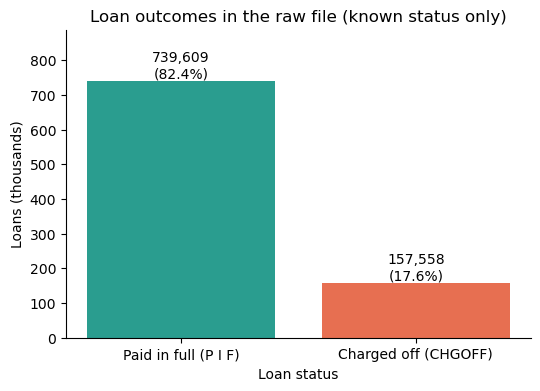

In [25]:
known = status_counts.drop(index=[np.nan], errors="ignore")
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Paid in full (P I F)", "Charged off (CHGOFF)"], known.loc[["P I F", "CHGOFF"], "loans"] / 1000,
       color=[P["teal"], P["red"]])
for x, v in enumerate(known.loc[["P I F", "CHGOFF"], "loans"]):
    ax.text(x, v / 1000, f"{v:,}\n({100 * v / known['loans'].sum():.1f}%)", ha="center", va="bottom")
ax.set_ylim(0, known["loans"].max() / 1000 * 1.2)
ax.set_title("Loan outcomes in the raw file (known status only)")
ax.set_xlabel("Loan status")
ax.set_ylabel("Loans (thousands)")
save_fig(fig, "fig01_class_balance.png")
plt.show()

Of the 897,167 loans with a known outcome, 157,558 (17.6%) were charged off. The classes are imbalanced roughly 4.7 to 1, so accuracy would be misleading (a model that approves everyone is 82% accurate). Notebooks 04 and 05 therefore use ROC-AUC, recall on defaults and the cost-based net value, and compare class weighting against no weighting.

## 13. Coverage over time and right-censoring

In [26]:
by_year = (evidence.groupby("approval_fy")["default"].agg(loans="size", default_rate="mean"))
by_year.loc[1985:2014].T

approval_fy,1985,1986,1987,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014
loans,"1,944.000","2,118.000","2,218.000","1,898.000","13,248.000","14,859.000","15,666.000","20,885.000","23,305.000","31,598.000","45,758.000","40,112.000","37,748.000","36,016.000","37,363.000","37,381.000","37,350.000","44,391.000","58,193.000","68,290.000","77,525.000","76,040.000","71,876.000","39,540.000","19,126.000","16,848.000","12,608.000","5,997.000","2,458.000",268.000
default_rate,0.404,0.408,0.435,0.494,0.065,0.045,0.028,0.022,0.019,0.022,0.028,0.041,0.060,0.082,0.099,0.114,0.119,0.117,0.145,0.180,0.253,0.350,0.428,0.412,0.208,0.137,0.079,0.057,0.029,0.019


Saved docs/figures/fig01_approval_year_coverage.png


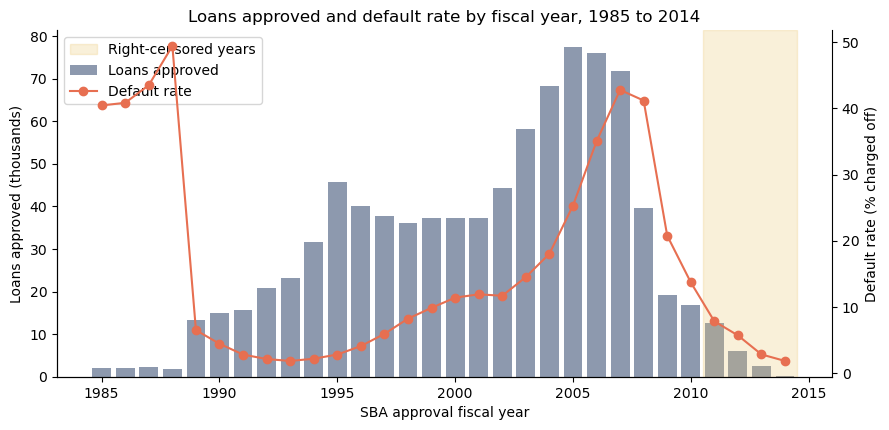

Loans approved before 1985: 6,537


In [27]:
years = by_year.loc[1985:2014]
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.bar(years.index, years["loans"] / 1000, color=P["grey"], label="Loans approved")
ax1.set_xlabel("SBA approval fiscal year")
ax1.set_ylabel("Loans approved (thousands)")
ax2 = ax1.twinx()
ax2.plot(years.index, 100 * years["default_rate"], color=P["red"], marker="o", label="Default rate")
ax2.set_ylabel("Default rate (% charged off)")
ax2.spines["right"].set_visible(True)
ax1.axvspan(2010.5, 2014.5, color=P["amber"], alpha=0.25, label="Right-censored years")
handles = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(handles, [h.get_label() for h in handles], loc="upper left")
ax1.set_title("Loans approved and default rate by fiscal year, 1985 to 2014")
save_fig(fig, "fig01_approval_year_coverage.png")
plt.show()
print(f"Loans approved before 1985: {(evidence['approval_fy'] < 1985).sum():,}")

Most loans were approved between 1989 and 2008, with a peak of 77,525 in 2005. The default rate rises from about 2% in the early 1990s to 42.8% for 2007 approvals, the cohort that met the 2008 to 2009 recession early in its life.

After 2009 the default rate falls quickly, to 2.9% in 2013 and 1.9% in 2014. This is not because those loans were safer. The file only contains loans whose outcome is known, so a loan approved in 2012 with a ten-year term can only appear if it has already been repaid early or has already failed. Loans still running at the data cut-off are missing, which biases recent years towards early repayment or early default. We cannot fix this in cleaning, but notebook 05 tests the model on later approval years separately and discusses the effect. The few loans approved before 1989 also have very high default rates (40% to 49%), probably for the same selection reason, and are a small share of the data.

## 14. Other observations

Two further points do not need a fix in cleaning but matter for feature engineering.

In [28]:
naics0 = raw["NAICS"] == 0
print(f"NAICS = 0: {naics0.sum():,} loans ({naics0.mean():.1%}), default rate {np.nanmean(default[naics0]):.1%}, "
      f"median approval FY {evidence.loc[naics0, 'approval_fy'].median():.0f}")
print(f"NAICS known: default rate {np.nanmean(default[~naics0]):.1%}, "
      f"median approval FY {evidence.loc[~naics0, 'approval_fy'].median():.0f}")
fc = raw["FranchiseCode"]
print(f"FranchiseCode 0: {(fc == 0).sum():,}, FranchiseCode 1: {(fc == 1).sum():,}, other codes: {(~fc.isin([0, 1])).sum():,}")
print("BankState codes that are not US states or DC:",
      sorted(set(raw["BankState"].dropna()) - set(raw["State"].dropna())))

NAICS = 0: 201,948 loans (22.5%), default rate 8.3%, median approval FY 1995
NAICS known: default rate 20.2%, median approval FY 2004
FranchiseCode 0: 208,835, FranchiseCode 1: 638,554, other codes: 51,775


BankState codes that are not US states or DC: ['AN', 'EN', 'GU', 'PR', 'VI']


NAICS is 0 for 201,948 loans (22.5%), mostly older loans approved before industry codes were recorded, and these default far less (8.3%) than loans with a known industry (20.2%). The code will be kept, and notebook 03 maps it to an explicit `Unknown` sector. FranchiseCode uses both 0 and 1 for "no franchise", which notebook 03 handles when building `IsFranchise`. A few bank states are territories or invalid codes (`AN`, `EN`, `GU`, `PR`, `VI`); they are kept as they are because bank state is only used to compare with the borrower's state.

## 15. Baseline quality table

Finally we run the quality assessment from `src/cleaning.py` on the raw file. Notebook 02 runs the same function on the cleaned table, so the two can be compared line by line.

In [29]:
quality_raw = quality_assessment(raw)
quality_raw

,group,check,value
0,Size,Rows,"899,164.000"
1,Size,Columns,27.000
2,Missing,Missing cells (original 27 columns),"751,248.000"
3,Missing,Missing cells (% of original cells),3.094
4,Missing,Missing cells excluding ChgOffDate,"14,783.000"
5,Missing,Rows with unknown MIS_Status,"1,997.000"
6,Format,Numeric or date columns stored as text,9.000
7,Invalid codes,RevLineCr: values outside the code list,"272,951.000"
8,Invalid codes,LowDoc: values outside the code list,"3,425.000"
9,Invalid codes,NewExist: values outside the code list,"1,034.000"


## 16. Data quality issues register

The register lists every issue found above with the size of the problem and the fix we plan for notebook 02. Numbers refer to the raw file of 899,164 loans.

| No. | Column(s) | Issue | Size in raw file | Planned fix in 02 |
|---|---|---|---|---|
| 1 | DisbursementGross, BalanceGross, ChgOffPrinGr, GrAppv, SBA_Appv | Currency stored as text (`$60,000.00 `) | 5 columns, all rows | Strip `$`, commas and spaces; convert to float |
| 2 | ApprovalDate, DisbursementDate, ChgOffDate | Dates as `dd-Mon-yy` text; default century rule puts 1960s approvals in the 2060s | 3 columns; 9 approval dates misread | Parse with explicit format and our century rule |
| 3 | DisbursementDate, ChgOffDate | Impossible dates outside 1960 to 2014 | 4 dates | Set to missing, flag `date_out_of_range` |
| 4 | ApprovalFY | Text with values `1976A` | 18 rows | Strip non-digits, convert to integer |
| 5 | MIS_Status | Outcome missing | 1,997 rows | Drop the rows (label unknown); create `Default` |
| 6 | RevLineCr | Codes `0`, `T` and 16 rare codes besides Y/N; missing values | 272,951 invalid, 4,528 missing | `0` to N and `T` to Y (evidence in section 7.1); rest to `Unknown`; keep `RevLineCr_raw` |
| 7 | LowDoc | Codes `0`, `C`, `S`, `A`, `R`, `1`; missing values | 3,425 invalid, 2,582 missing | Keep Y/N, all else `Unknown` |
| 8 | NewExist | Code 0 and missing | 1,034 coded 0, 136 missing | 1 Existing, 2 New, else `Unknown` |
| 9 | UrbanRural | Code 0 (undefined) | 323,167 rows | 1 Urban, 2 Rural, 0 `Unknown` |
| 10 | NoEmp | Placeholder 9999 and values above the 99.9th percentile (300) | 4 placeholders, 885 above 300 | Set to missing; impute sector median; flag `noemp_imputed` |
| 11 | Term | Term of 0 months; 91.1% of these loans defaulted | 810 rows | Impute median term of the same loan-size band; flag `term_imputed`, which must not become a feature |
| 12 | CreateJob, RetainedJob | Extreme values up to 8,800 and 9,500 | 870 and 900 rows above the 99.9th percentile | Winsorise at the 99.9th percentile |
| 13 | DisbursementDate, ApprovalDate | Disbursement more than 30 days before approval | 135 rows | Keep, flag `disb_before_approval` |
| 14 | SBA_Appv, GrAppv | Guarantee above the loan amount | 0 rows | Cap at `GrAppv` as a safeguard |
| 15 | ChgOffDate, MIS_Status | Charge-off date disagrees with the status | 4,974 rows | Keep `MIS_Status` as the label, flag `chgoff_mismatch` |
| 16 | Zip | Zip of 0 | 283 rows | Set to missing |
| 17 | DisbursementGross | Zero disbursement | 196 rows | Removed with the unknown-status rows (issue 5) |
| 18 | Name, City, State, ApprovalDate, GrAppv | Near-duplicate loans | 1,266 extra rows | Keep the first of each group |
| 19 | State | Missing borrower state | 14 rows | Fill from the three-digit ZIP prefix when one state dominates it, else `Unknown` |
| 20 | Bank, BankState, City, Name | Missing text | 1,559, 1,566, 30, 3 rows | Fill with `Unknown` |
| 21 | NAICS | Industry code 0 | 201,948 rows | Keep; mapped to sector `Unknown` in 03 |
| 22 | FranchiseCode | 0 and 1 both mean no franchise | 0 and 1 together on 847,389 rows | Keep; `IsFranchise` in 03 treats both as no franchise |
| 23 | ChgOffDate, ChgOffPrinGr, BalanceGross, MIS_Status | Post-outcome information (leakage) | 4 columns | Kept in the clean file for checks only; excluded through `config.LEAKAGE_COLUMNS` |
| 24 | MIS_Status | Class imbalance, 17.6% default | 157,558 of 897,167 known | No change in cleaning; handled with metrics and class weights in 04 and 05 |
| 25 | ApprovalFY | Right-censoring of recent cohorts | Default rate under 8% from 2011 | No change in cleaning; temporal validation in 05 |